In [1]:
import os
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt

DATASET_PATH = "../data/raw/GVLiD/DATASET"

classes = ["healthy", "esca", "Black rot", "leaf blight"]

for category in classes:
    folder = os.path.join(DATASET_PATH, category)
    images = os.listdir(folder)

    print(category, ":", len(images))

healthy : 1109
esca : 888
Black rot : 808
leaf blight : 672


In [2]:
import os
from PIL import Image
import pandas as pd

DATASET_PATH = "../data/raw/GVLiD/DATASET"

image_data = []

for category in classes:
    folder = os.path.join(DATASET_PATH, category)

    for filename in os.listdir(folder):
        filepath = os.path.join(folder, filename)

        try:
            with Image.open(filepath) as img:
                image_data.append({
                    "filename": filename,
                    "class": category,
                    "width": img.width,
                    "height": img.height,
                    "mode": img.mode,
                    "format": img.format
                })

        except Exception as e:
            print("Error:", filepath, e)

df_images = pd.DataFrame(image_data)

print("Total valid images:", len(df_images))
print("\nImage dimensions:")
print(df_images[["width", "height"]].describe())

print("\nImage modes:")
print(df_images["mode"].value_counts())

print("\nImage formats:")
print(df_images["format"].value_counts())

Total valid images: 3477

Image dimensions:
        width  height
count  3477.0  3477.0
mean   1080.0  1080.0
std       0.0     0.0
min    1080.0  1080.0
25%    1080.0  1080.0
50%    1080.0  1080.0
75%    1080.0  1080.0
max    1080.0  1080.0

Image modes:
mode
RGB    3477
Name: count, dtype: int64

Image formats:
format
JPEG    3477
Name: count, dtype: int64


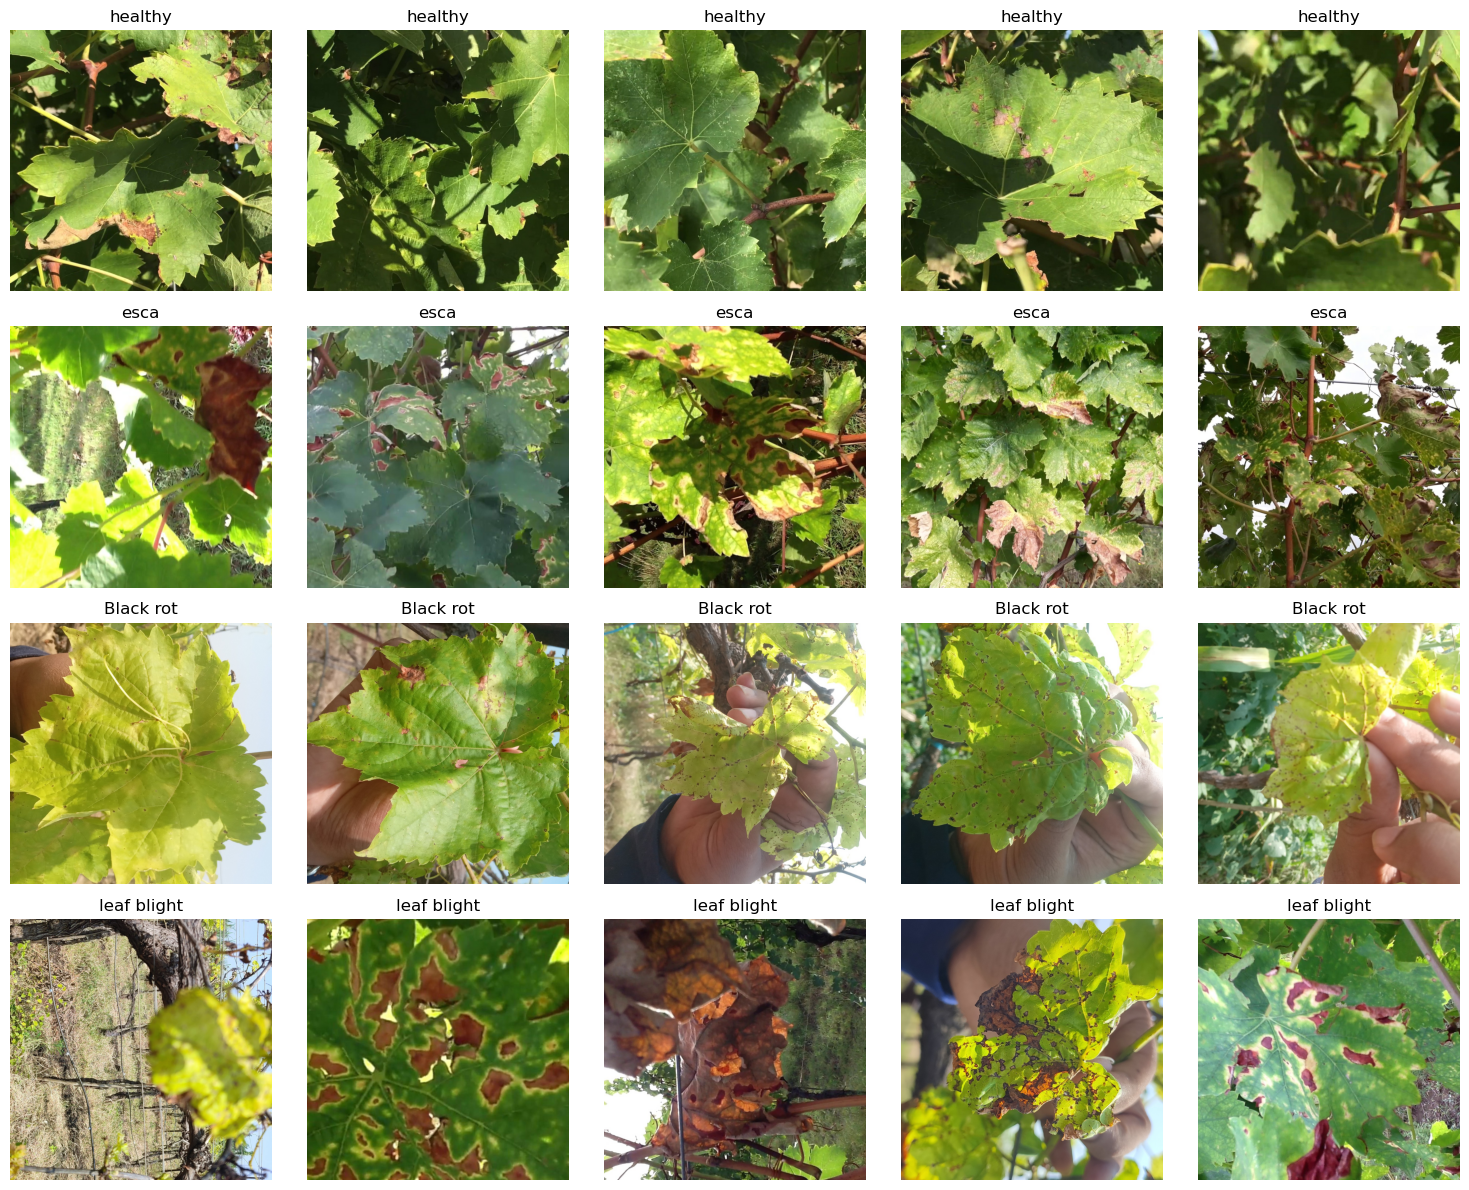

In [3]:
import random
from PIL import Image
import matplotlib.pyplot as plt
import os

fig, axes = plt.subplots(4, 5, figsize=(15, 12))

for row, category in enumerate(classes):
    folder = os.path.join(DATASET_PATH, category)
    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    samples = random.sample(images, 5)

    for col, filename in enumerate(samples):
        img_path = os.path.join(folder, filename)

        with Image.open(img_path) as img:
            axes[row, col].imshow(img.copy())

        axes[row, col].set_title(category)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [4]:
import numpy as np
from PIL import Image

def preprocess_image(image_path, size=(224, 224)):
    with Image.open(image_path) as img:
        img = img.convert("RGB")
        img = img.resize(size)

        image_array = np.array(img, dtype=np.float32)

        # Normalize pixel values
        image_array = image_array / 255.0

    return image_array

In [5]:
sample_path = os.path.join(
    DATASET_PATH,
    "healthy",
    os.listdir(os.path.join(DATASET_PATH, "healthy"))[0]
)

processed_image = preprocess_image(sample_path)

print("Shape:", processed_image.shape)
print("Minimum:", processed_image.min())
print("Maximum:", processed_image.max())
print("Data type:", processed_image.dtype)

Shape: (224, 224, 3)
Minimum: 0.0
Maximum: 1.0
Data type: float32


In [6]:
import os
from PIL import Image

OUTPUT_PATH = "../data/processed/GVLiD_224"

os.makedirs(OUTPUT_PATH, exist_ok=True)

processed_count = 0
failed_images = []

for category in classes:

    input_folder = os.path.join(DATASET_PATH, category)
    output_folder = os.path.join(OUTPUT_PATH, category)

    os.makedirs(output_folder, exist_ok=True)

    for filename in os.listdir(input_folder):

        input_file = os.path.join(input_folder, filename)
        output_file = os.path.join(output_folder, filename)

        try:
            with Image.open(input_file) as img:
                img = img.convert("RGB")
                img = img.resize((224, 224))
                img.save(output_file, quality=95)

            processed_count += 1

        except Exception as e:
            failed_images.append(filename)
            print("Failed:", filename, e)

print("Total processed:", processed_count)
print("Failed images:", len(failed_images))
print("Output location:", OUTPUT_PATH)

Total processed: 3477
Failed images: 0
Output location: ../data/processed/GVLiD_224


In [7]:
from PIL import Image
import os

sample_file = os.path.join(
    OUTPUT_PATH,
    "healthy",
    os.listdir(os.path.join(OUTPUT_PATH, "healthy"))[0]
)

with Image.open(sample_file) as img:
    print("Image size:", img.size)
    print("Image mode:", img.mode)

Image size: (224, 224)
Image mode: RGB


In [8]:
import os
from PIL import Image
import pandas as pd

verification = []

for category in classes:
    folder = os.path.join(OUTPUT_PATH, category)

    count = 0
    invalid = 0

    for filename in os.listdir(folder):
        filepath = os.path.join(folder, filename)

        try:
            with Image.open(filepath) as img:
                if img.size == (224, 224) and img.mode == "RGB":
                    count += 1
                else:
                    invalid += 1
        except Exception:
            invalid += 1

    verification.append({
        "Class": category,
        "Valid Images": count,
        "Invalid Images": invalid
    })

verification_df = pd.DataFrame(verification)
print(verification_df)
print("\nTotal valid:", verification_df["Valid Images"].sum())
print("Total invalid:", verification_df["Invalid Images"].sum())

         Class  Valid Images  Invalid Images
0      healthy          1109               0
1         esca           888               0
2    Black rot           808               0
3  leaf blight           672               0

Total valid: 3477
Total invalid: 0
